#  Generate and Validate the Synthetic Cohort

**Thesis:** Clinical Decision Support System (CDSS) with a Family Health Risk Score (FHRS)
**Frozen cohort:** v11 · `SEED = 42` · SHA-256 `23d28b00c57b3895f914526d446e8623b4a96b8adc0996a51e6306821fbcb5e3`

## What this notebook is for

This notebook is the **visual companion** to the synthetic data pipeline. It does four things:

1. **Generates** the synthetic patient cohort by running `generate_cohort.py`.
2. **Loads** the result (`experiment/data/raw/cohort.parquet`) and shows the first rows.
3. **Draws three charts** so a person can *see* what the validation gates measure: missingness, biomarker correlations, and distribution shapes.
4. **Proves determinism** by generating the cohort twice and checking that both files have the same SHA-256 fingerprint.

The formal pass/fail checks are **not** run here. They are run from the terminal by `validate.py` (10 gates) and `check_fixes.py`. The charts here make those numbers visible and easy to explain in Chapter 3.

## Why a synthetic cohort?

The CDSS needs patient records with biomarkers, family history and diagnoses to train and test the cascaded XGBoost models. Real records are slow to access, carry privacy risk, and have unknown "true" relationships. A synthetic cohort is generated from **written, documented rules**, so:

- no real patient can be identified;
- every relationship in the data (for example, *higher HbA1c → more likely T2D*) is known and can be checked;
- the exact same cohort can be rebuilt by anyone with the code and the seed.

## What the cohort contains

| Part | Content |
| --- | --- |
| Patients / visits | 15,000 patients, 23,996 visits (each patient has one or more yearly visits) |
| Demographics | `patient_id`, `biological_sex`, `age` (three balanced age groups around 32, 54 and 74) |
| CVD panel | BMI, systolic/diastolic BP, resting HR, total cholesterol, HDL, LDL, triglycerides (`tg`), eGFR |
| T2D panel | HbA1c, fasting plasma glucose (`fpg`) |
| RESP panel | FEV1, FVC, FEV1/FVC ratio, SpO₂ |
| NEURO panel | PHQ-9, GAD-7, MMSE, sleep hours |
| Family history | FHRS score and FHRS band (0–4) for each disease, computed with the CDSS data-dictionary formula |
| Outcomes | `y_cvd`, `y_t2d`, `y_resp`, `y_neuro` (0 = no diagnosis, 1 = diagnosed; once diagnosed, stays diagnosed) |
| Measured flags | `*_measured` columns: 1 = test done at that visit, 0 = not done (value is blank) |

## How the pipeline builds it

| Step | Module | What it does |
| --- | --- | --- |
| 1 | `distributions.py` | Draws age, sex and all biomarkers, with realistic links (e.g. BMI raises SBP and TG, lowers HDL) |
| 2 | `fhrs.py` | Simulates relatives and computes the FHRS score and band per disease |
| 3 | `dag.py` | Turns biomarkers + FHRS into a disease risk and draws the four outcome labels at fixed prevalences |
| 4 | `longitudinal.py` | Adds follow-up visits with yearly drift (age +1, SBP up, eGFR down, …) |
| 5 | `dag.py` | Updates outcomes across visits (new diagnoses can appear, none disappear) |
| 6 | `missingness.py` | Blanks out tests that were not done: routine labs ~40%, specialized tests ~60% |

## How to run

Use **Kernel → Restart & Run All**. Outputs were cleared on purpose: the old saved outputs came from an earlier version (v8: digest `e98d963a…`, 51 columns) and no longer match the frozen cohort.

## Setup — imports and paths

All paths are relative to the `experiment/notebooks/` folder.

`COHORT_OUT` tells `generate_cohort.py` exactly where to write the cohort. Without it, the generator writes to a path relative to wherever it is started from, which from this folder is **not** the file the notebook reads. `sys.executable` makes sure the generator runs with the same Python environment as this notebook.

In [1]:
import os
import sys
import hashlib

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import missingno as msno

# Define relative paths based on the experiment/ directory structure
DATA_PATH = "../data/raw/cohort.parquet"
GENERATE_SCRIPT = "../src/synthetic/generate_cohort.py"
VALIDATE_SCRIPT = "../src/synthetic/validate.py"

# Make the generator write to the same file this notebook reads
os.environ["COHORT_OUT"] = os.path.abspath(DATA_PATH)
print("Cohort file:", os.environ["COHORT_OUT"])

Cohort file: /home/nirmata/Desktop/thesis draft-1/experiment/data/raw/cohort.parquet


## Step 1 — Generate the cohort

Runs the full pipeline once. Each emoji line in the output is one module from the table above finishing its step.

In [2]:
# Run the pipeline to generate the synthetic cohort
print("Executing Synthetic Cohort Generation Pipeline...")
!"{sys.executable}" "{GENERATE_SCRIPT}"

Executing Synthetic Cohort Generation Pipeline...
🚀 INITIATING MODULAR SYNTHETIC COHORT GENERATION PIPELINE...
🧬 Generating Demographics and Biomarkers...
🧬 Computing FHRS Scores...
🦠 Injecting Disease Logits & Outcomes...
⏳ Expanding to Longitudinal Visits...
🔁 Updating Outcomes Across Visits (incident diagnosis)...
🕳️ Injecting Clinical Missingness...

✅ MODULAR SYNTHESIS COMPLETE!
📊 Total Encounters: 23996 | Unique Patients: 15000
📁 Output: /home/nirmata/Desktop/thesis draft-1/experiment/data/raw/cohort.parquet
🔒 SHA-256 Digest: 23d28b00c57b3895f914526d446e8623b4a96b8adc0996a51e6306821fbcb5e3


### What the output means

Expected output for the frozen v11 cohort:

```text
✅ MODULAR SYNTHESIS COMPLETE!
📊 Total Encounters: 23996 | Unique Patients: 15000
📁 Output: <your path>/experiment/data/raw/cohort.parquet
🔒 SHA-256 Digest: 23d28b00c57b3895f914526d446e8623b4a96b8adc0996a51e6306821fbcb5e3
```

- **Total Encounters 23,996** — the number of visits (rows). It is more than 15,000 because some patients have follow-up visits.
- **Output** — must end in `experiment/data/raw/cohort.parquet`. Any other path means `COHORT_OUT` was not picked up.
- **SHA-256 Digest** — a fingerprint of the file's exact bytes. If even one value changed, the digest would be completely different. A digest other than `23d28b00…` means the code or a library version differs from the frozen run.

## Step 2 — Load the cohort

Reads the parquet file into a table (`df`, all visits) and keeps a second table of first visits only (`base`). The charts use `base`, so each patient is counted once and the numbers match the terminal checks.

In [3]:
# Load the generated parquet file
df = pd.read_parquet(DATA_PATH)
base = df[df["visit_number"] == 1]          # baseline visit: one row per patient
print(f"Cohort loaded successfully! Shape: {df.shape} (visits x columns)")
print(f"Baseline visits: {len(base)} (one per patient)")
display(df.head())

Cohort loaded successfully! Shape: (23996, 49) (visits x columns)
Baseline visits: 15000 (one per patient)


,patient_id,biological_sex,age,bmi,systolic_bp,diastolic_bp,resting_hr,total_cholesterol,hdl,ldl,...,days_since_baseline,ldl_measured,tg_measured,fpg_measured,total_cholesterol_measured,bmi_measured,spirometry_measured,spo2_measured,phq9_measured,gad7_measured
0,PT-20260000,0,59,28.328909,127.095472,77.423213,79.334462,NaN,74.292118,87.97938,...,0,1,0,1,0,1,1,0,1,0
1,PT-20260000,0,60,28.478909,127.695472,77.423213,79.334462,182.271499,74.292118,87.97938,...,365,1,0,0,1,1,1,0,0,0
2,PT-20260001,1,68,33.711067,150.112227,84.054140,84.219626,NaN,67.000298,NaN,...,0,0,0,1,0,1,1,1,0,1
3,PT-20260002,0,34,NaN,101.441624,65.602261,72.012968,NaN,82.352022,NaN,...,0,0,1,0,0,0,1,1,0,0
4,PT-20260002,0,35,28.461441,102.041624,65.602261,72.012968,NaN,82.352022,NaN,...,365,0,0,0,0,1,1,0,0,0


### What the output means

Expected: `Shape: (23996, 49)` and `Baseline visits: 15000`.

- **Each row is one visit**, not one patient. The same `patient_id` can appear on several rows, with age one year higher on each follow-up.
- **`NaN` means the test was not done at that visit.** The matching `*_measured` column is 0 on that row and 1 when the value is present.
- Age, sex, blood pressure, resting HR, HDL, eGFR, HbA1c, MMSE, sleep, FHRS columns and outcomes are **never** blank.
- Spirometry is one test with three values, so `fev1`, `fvc` and `fev1_fvc_ratio` are always blank or present **together**, under one flag: `spirometry_measured`.

## Chart 1 — Missingness map

**Related gate:** Gate 8 (overall missingness must be 8–12%).

Real clinics do not run every test at every visit. The pipeline blanks out values per **test**, not per number: a routine lab is skipped ~40% of the time and a specialized test ~60% of the time.

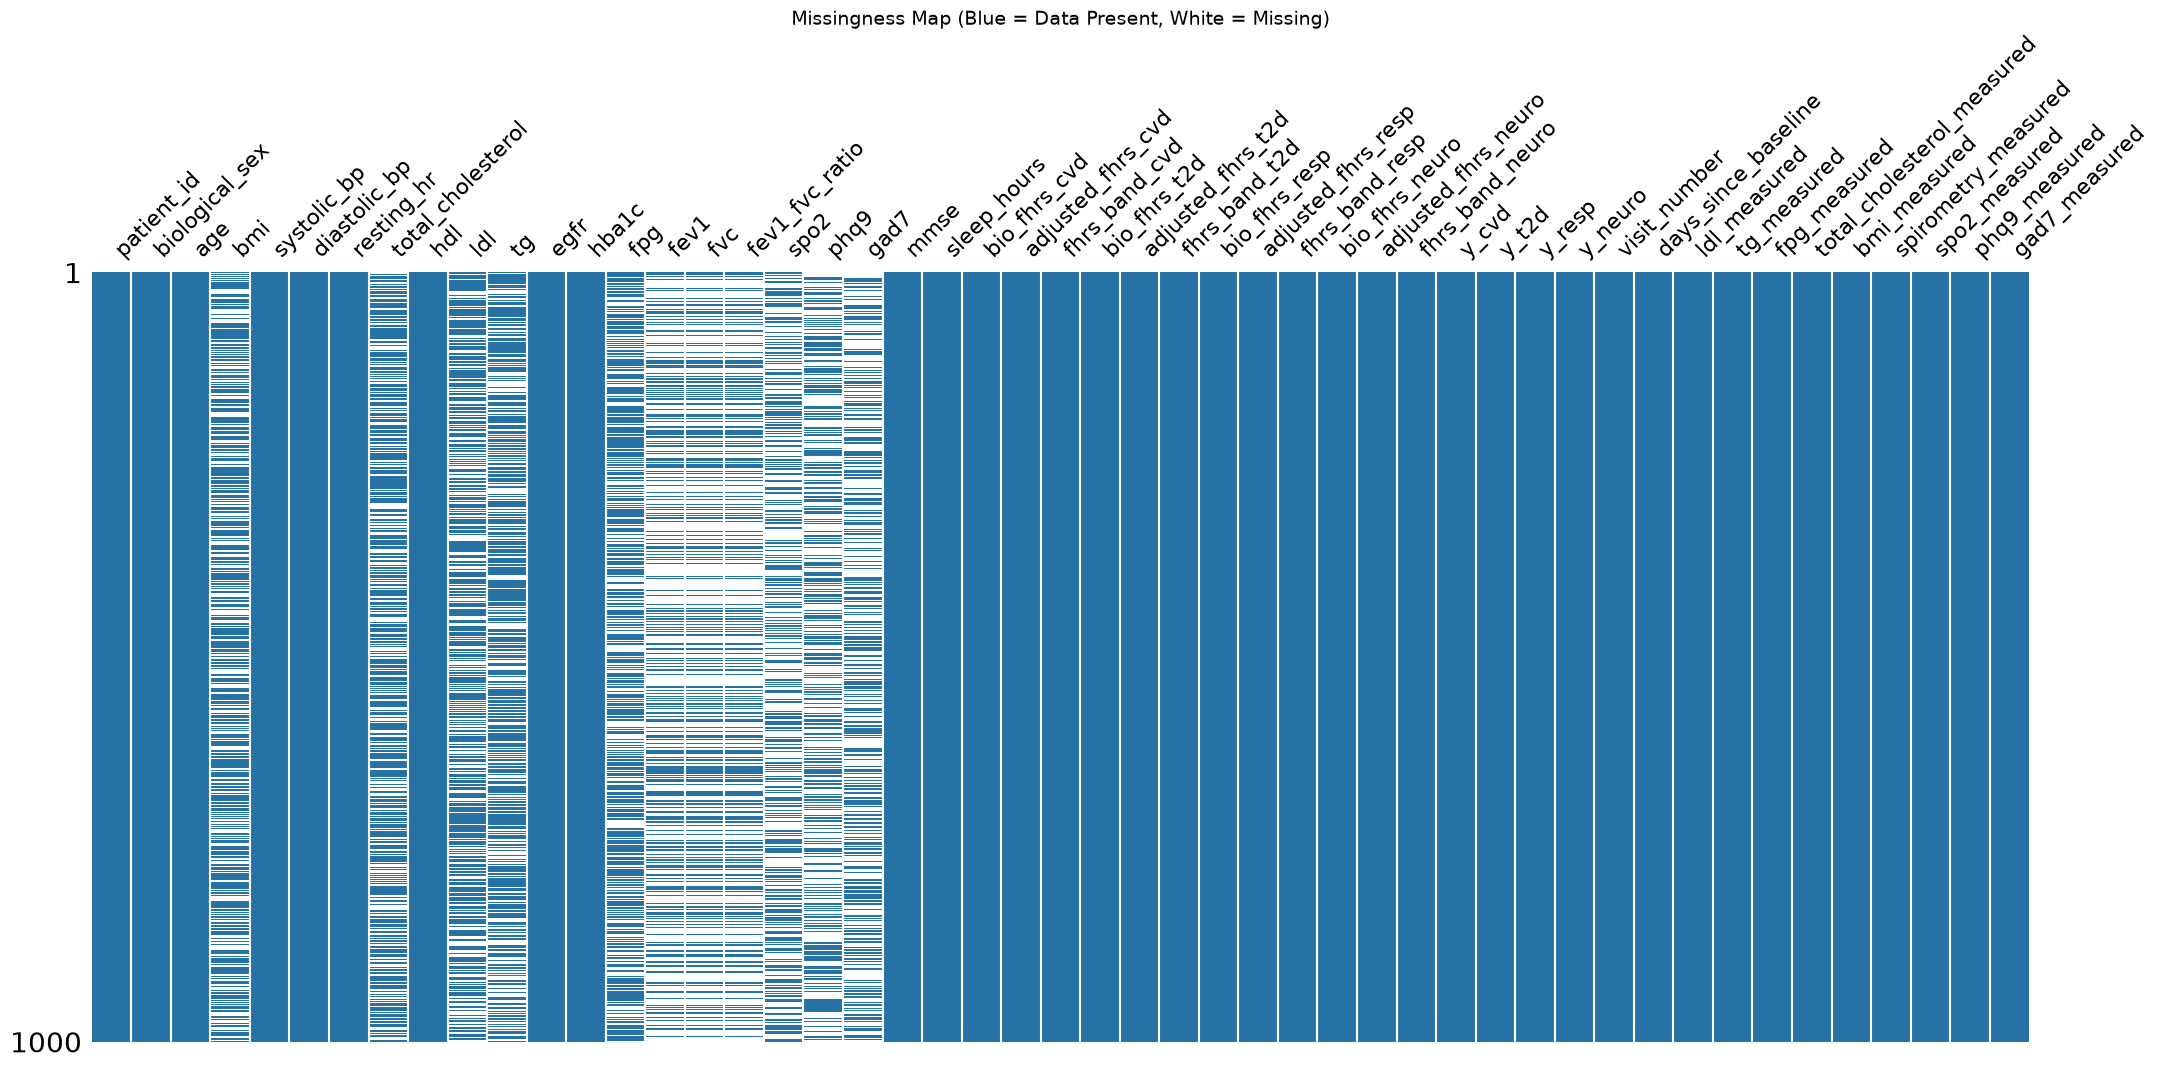

Missing % per column (all visits): {'bmi': 40.2, 'total_cholesterol': 40.0, 'ldl': 40.7, 'tg': 40.3, 'fpg': 40.4, 'fev1': 60.1, 'fvc': 60.1, 'fev1_fvc_ratio': 60.1, 'spo2': 59.9, 'phq9': 59.8, 'gad7': 59.9}
Overall missingness: 11.5%


In [4]:
# Shows Gate 8 visually: which columns have gaps and how large they are
# Sampling 1000 visits to keep the rendering fast
msno.matrix(df.sample(min(1000, len(df)), random_state=42), labels=True, sparkline=False,
            color=(0.15, 0.45, 0.65))
plt.title("Missingness Map (Blue = Data Present, White = Missing)", fontsize=14)
plt.show()

miss = (df.isna().mean() * 100).round(1)
print("Missing % per column (all visits):", miss[miss > 0].to_dict())
print(f"Overall missingness: {df.isna().mean().mean() * 100:.1f}%")

### How to read it

Each vertical strip is one column. Each horizontal line is one visit (1,000 random visits). Blue means a value is present and white means it is missing.

| What you should see | Columns | Expected missing |
| --- | --- | --- |
| Solid blue strips | demographics, BP, resting HR, HDL, eGFR, HbA1c, MMSE, sleep, FHRS, outcomes, all `*_measured` flags | 0% |
| About 40% white | `bmi`, `total_cholesterol`, `ldl`, `tg`, `fpg` (routine labs) | ~40% |
| About 60% white | `spo2`, `phq9`, `gad7` (specialized tests) | ~60% |
| About 60% white, **same rows** | `fev1`, `fvc`, `fev1_fvc_ratio` (one spirometry test) | ~60% |

The printed per-column numbers should be close to 40.0 and 60.0, and overall missingness should be about **11.5%**, inside Gate 8's 8–12% band.

**Known simplification (Chapter 3 limitations):** `ldl`, `total_cholesterol` and `tg` are blanked independently, and HDL is never blank. In real practice these come from one lipid panel.

## Chart 2 — Biomarker correlation heatmap

**Related gates:** Gate 3 (correlation signs), plus the v10–v11 realism checks.

A correlation (*r*) runs from −1 to +1. A positive *r* means two values rise together, a negative *r* means one falls as the other rises, and 0 means no linear link. The pipeline builds in links that are known from clinical practice, and this chart shows whether they came out at the intended strength.

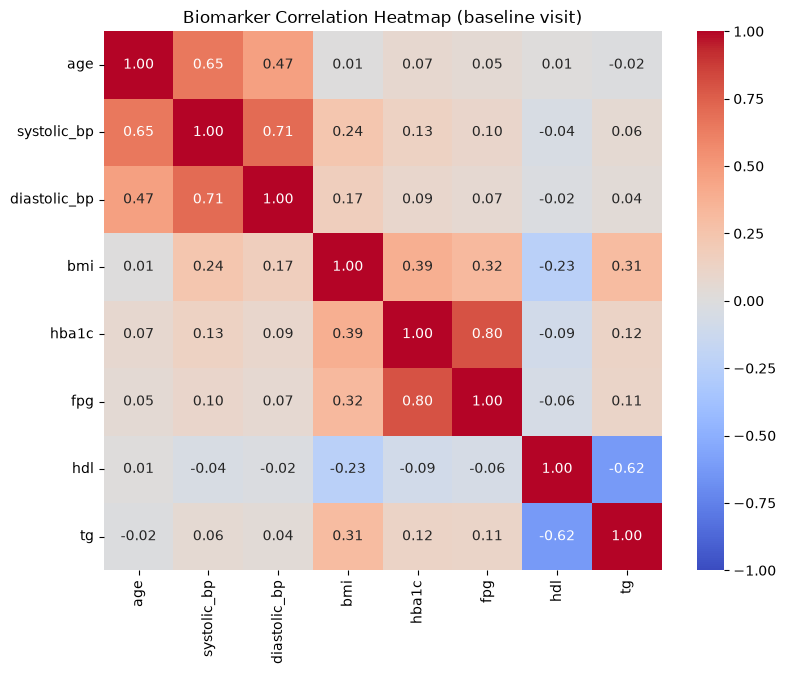

In [5]:
# Shows Gate 3 visually: biologically expected correlations (baseline visit)
target_cols = ['age', 'systolic_bp', 'diastolic_bp', 'bmi', 'hba1c', 'fpg', 'hdl', 'tg']
available_cols = [c for c in target_cols if c in base.columns]

if available_cols:
    plt.figure(figsize=(9, 7))
    corr_matrix = base[available_cols].corr()   # pairwise: uses visits where both values exist
    sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', vmin=-1, vmax=1, center=0, fmt=".2f")
    plt.title("Biomarker Correlation Heatmap (baseline visit)")
    plt.show()
else:
    print("Warning: Target columns for correlation not yet generated.")

### How to read it

Each square is the *r* between its row and column. Red is positive, blue is negative and white is near zero. The diagonal is always 1.00 (a value with itself).

Expected values for the frozen v11 cohort (from the v11 terminal run):

| Pair | Expected *r* | Why it is built in |
| --- | --- | --- |
| SBP – DBP | 0.71 | DBP follows SBP only partly: DBP = 0.5·SBP + 15 + noise |
| BMI – SBP | 0.24 | +0.5 mmHg per kg/m² of BMI |
| BMI – HDL | −0.23 | −0.6 mg/dL per kg/m² of BMI |
| BMI – TG | 0.31 | +1.0 mg/dL per kg/m² directly, +0.9 more through lower HDL |
| HDL – TG | −0.62 | Gate 3 requires this to be below −0.30 |
| HbA1c – FPG | 0.80 | FPG is generated from HbA1c |

Also expect **age – SBP** to be clearly positive (SBP rises 0.5 mmHg per year of age) and **BMI – HbA1c** to be positive (higher BMI raises the chance of being in the dysglycaemic group).

If the heatmap shows the same signs and values close to these, the biological relationships came out as designed.

## Chart 3 — Distribution shapes

**Related gates:** Gate 2 (BMI quartiles match the reference) and Gate 9 (enough patients in every age × sex group).

A histogram shows how many patients fall at each value. The shape should look clinically plausible, not like a flat block or a perfect textbook bell.

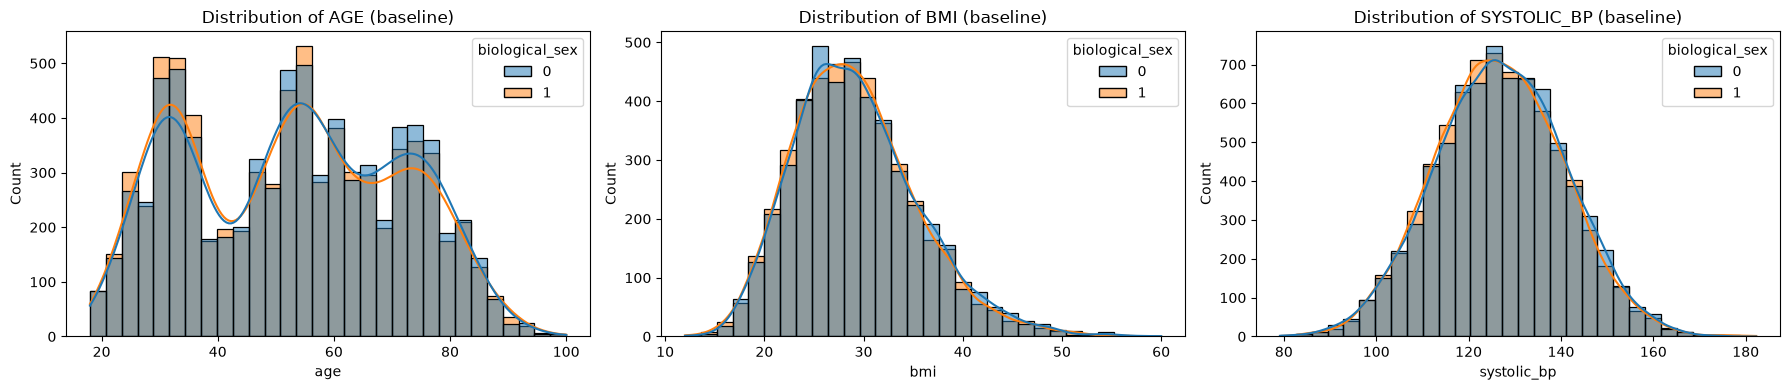

BMI quartiles (p25, p50, p75): [24.7, 28.6, 33.0]
Mean SBP: 126.8 mmHg


In [6]:
# Shows Gate 2 / Gate 9 visually: distribution shapes at baseline, split by sex
dist_cols = ['age', 'bmi', 'systolic_bp']
available_dist_cols = [c for c in dist_cols if c in base.columns]

if available_dist_cols:
    fig, axes = plt.subplots(1, len(available_dist_cols), figsize=(18, 4))
    if len(available_dist_cols) == 1:
        axes = [axes]

    for ax, col in zip(axes, available_dist_cols):
        hue_col = 'biological_sex' if 'biological_sex' in base.columns else None
        sns.histplot(data=base, x=col, hue=hue_col, kde=True, ax=ax, bins=30)
        ax.set_title(f"Distribution of {col.upper()} (baseline)")

    plt.tight_layout()
    plt.show()

print("BMI quartiles (p25, p50, p75):", np.percentile(base['bmi'].dropna(), [25, 50, 75]).round(1).tolist())
print(f"Mean SBP: {base['systolic_bp'].mean():.1f} mmHg")

### How to read it

The two colours are the two values of `biological_sex` (0 and 1). The smooth line is a density curve over the bars.

- **AGE — three humps** near 32, 54 and 74. The generator draws three age groups of about equal size, so Gate 9 always has enough patients in every age × sex cell (smallest cell: 2,185).
- **BMI — skewed to the right.** Most patients are between about 22 and 38, with a longer tail toward high BMI, as in adult populations. Expected quartiles are about **[24.7, 28.6, 33.0]**, against the reference 24.8 / 28.5 / 33.2 used by Gate 2. Bars are lower than for age because BMI is missing for ~40% of patients.
- **SYSTOLIC_BP — roughly bell-shaped**, mean about **127 mmHg**, range about 79–182. It sits a little to the right because SBP rises with age and BMI.
- **The two sexes overlap almost exactly.** This is expected: the generator does not use sex when drawing any biomarker. It is a simplification to state in the Chapter 3 limitations.

## Step 3 — Determinism check (SHA-256)

**Related gate:** Gate 10 (determinism with `SEED = 42`).

A random generator started with the same seed produces the same numbers every time. If the pipeline is fully seeded, two runs must produce **byte-identical** files. This cell hashes the file, regenerates it (overwriting the same file), hashes it again, and compares the two hashes.

In [7]:
def get_sha256(filepath):
    hasher = hashlib.sha256()
    with open(filepath, 'rb') as f:
        hasher.update(f.read())
    return hasher.hexdigest()

# 1. Hash the first run
hash_run_1 = get_sha256(DATA_PATH)
print(f"Run 1 SHA-256 Digest: {hash_run_1}")

# 2. Generate the cohort a second time (overwrites DATA_PATH via COHORT_OUT)
mtime_before = os.path.getmtime(DATA_PATH)
print("\nExecuting Run 2 to test cryptographic determinism (SEED=42)...")
!"{sys.executable}" "{GENERATE_SCRIPT}"

# 3. Hash the second run
assert os.path.getmtime(DATA_PATH) > mtime_before, "Run 2 did not rewrite DATA_PATH - check COHORT_OUT"
hash_run_2 = get_sha256(DATA_PATH)
print(f"Run 2 SHA-256 Digest: {hash_run_2}\n")

# 4. Compare
if hash_run_1 == hash_run_2:
    print("✅ PASS: Cryptographic determinism verified. Digests match perfectly.")
else:
    print("❌ FAIL: Digests do not match! Check your stochastic generators for unseeded randomness.")

Run 1 SHA-256 Digest: 23d28b00c57b3895f914526d446e8623b4a96b8adc0996a51e6306821fbcb5e3

Executing Run 2 to test cryptographic determinism (SEED=42)...
🚀 INITIATING MODULAR SYNTHETIC COHORT GENERATION PIPELINE...
🧬 Generating Demographics and Biomarkers...
🧬 Computing FHRS Scores...
🦠 Injecting Disease Logits & Outcomes...
⏳ Expanding to Longitudinal Visits...
🔁 Updating Outcomes Across Visits (incident diagnosis)...
🕳️ Injecting Clinical Missingness...

✅ MODULAR SYNTHESIS COMPLETE!
📊 Total Encounters: 23996 | Unique Patients: 15000
📁 Output: /home/nirmata/Desktop/thesis draft-1/experiment/data/raw/cohort.parquet
🔒 SHA-256 Digest: 23d28b00c57b3895f914526d446e8623b4a96b8adc0996a51e6306821fbcb5e3
Run 2 SHA-256 Digest: 23d28b00c57b3895f914526d446e8623b4a96b8adc0996a51e6306821fbcb5e3

✅ PASS: Cryptographic determinism verified. Digests match perfectly.


### What the output means

Expected:

```text
Run 1 SHA-256 Digest: 23d28b00c57b3895f914526d446e8623b4a96b8adc0996a51e6306821fbcb5e3
...
Run 2 SHA-256 Digest: 23d28b00c57b3895f914526d446e8623b4a96b8adc0996a51e6306821fbcb5e3

✅ PASS: Cryptographic determinism verified. Digests match perfectly.
```

- **Matching digests** prove that the whole cohort (every patient, value, blank and label) is reproducible from the code and the seed. This is what lets an examiner rebuild the exact dataset used in the thesis.
- The `assert` line checks that Run 2 really rewrote the file. In the earlier version of this notebook the generator wrote to a different path, so this cell compared the same untouched file twice and could never fail.
- If both runs match each other but differ from `23d28b00…`, the run is still deterministic. The difference then comes from a code change or a different library version, and `audit_modules.py` will show which file changed.

## Results at a glance

| Check | Expected (frozen v11) | Gate |
| --- | --- | --- |
| Visits / patients / columns | 23,996 / 15,000 / 49 | — |
| Overall missingness | ~11.5% | Gate 8 (8–12%) |
| Routine / specialized missingness | ~40% / ~60%, spirometry missing together | Gate 8 |
| HDL – TG correlation | −0.62 | Gate 3 (< −0.30) |
| SBP–DBP, BMI–SBP, BMI–HDL, BMI–TG | 0.71, 0.24, −0.23, 0.31 | realism checks |
| BMI quartiles | ~[24.7, 28.6, 33.0] | Gate 2 |
| Age groups | three humps at ~32 / 54 / 74 | Gate 9 |
| SHA-256, two runs | identical, `23d28b00…bcb5e3` | Gate 10 |

**Checked in the terminal, not in this notebook:** outcome prevalences (Gate 4), single-feature dominance (Gate 5), oracle AUROC (Gate 6), FHRS ablation (Gate 7), FHRS bands, label monotonicity and severe-range checks. Run them with:

```bash
uv run python experiment/src/synthetic/validate.py
uv run python experiment/src/synthetic/check_fixes.py
```